# 00 - Data check (Week 1)

**Goal:** before any duplicate audit or training, confirm exactly what is inside `./data/`.

1. Find every dataset version folder and count images per class and per Training/Testing split.
2. Identify which folder is **v1** (original Kaggle release, 7,023 images, contains duplicates) and which is **v2** (cleaned release, ~7,200 images).
3. Open every image to find corrupt files; report image sizes, colour modes and file types.
4. Plot sample images per class and the class counts.

`./data/` is **read-only**: this notebook only reads it. Plots go to `outputs/plots/week1/`. All helper code lives in `src/data.py`.

In [1]:
# Setup: make the project root importable and work from it, so 'data/' and 'outputs/' resolve.
import os, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image as ShowImage, display
from src import data as d

d.set_seed(d.SEED)                      # seed 42 everywhere
DATA_ROOT = 'data'
PLOT_DIR = Path('outputs/plots/week1')
print('Project root:', ROOT)

Project root: D:\Brain-Tumor


D:\Brain-Tumor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Find versions and count images
Folder names are matched case-insensitively (`Glioma`, `glioma`, `glioma_tumor` all count as glioma).

In [2]:
versions = d.find_versions(DATA_ROOT)
print('Version folders found:', versions)

files = d.list_images(DATA_ROOT)          # one row per image file
print('Total image files:', len(files))
counts = d.count_table(files)
counts

Version folders found: ['v1', 'v2']


Total image files: 14223


label             glioma  meningioma  notumor  pituitary  Total
version split                                                  
v1      Testing      300         306      405        300   1311
        Training    1321        1339     1595       1457   5712
v2      Testing      400         400      400        400   1600
        Training    1400        1400     1400       1400   5600

**What the counts show**
- Two version folders were found: `v1` and `v2`, 14,223 images in total.
- **v1 is unbalanced.** Per class (Training + Testing): glioma 1,621, meningioma 1,645, notumor 2,000, pituitary 1,757.
  notumor has the most images in both splits (1,595 Training / 405 Testing).
- **v2 is perfectly balanced:** 1,400 Training + 400 Testing for every class (1,800 per class).
- Train/test share: v1 = 5,712 / 1,311 (81% / 19%); v2 = 5,600 / 1,600 (78% / 22%).
- v2 is **not** just v1 with duplicates removed: compared with v1 it has +179 glioma, +155 meningioma,
  +43 pituitary and **-200 notumor** images (+177 in total). So images were both added and removed;
  the Week 2 duplicate audit will measure how much v1 and v2 overlap.

## 2. Which folder is v1 and which is v2?
Each folder is matched to the known release with the closest total (v1 = 7,023, v2 = 7,200).

In [3]:
d.identify_versions(files)

,total,looks_like,expected,difference
v1,7023,v1,7023,0
v2,7200,v2,7200,0


## 3. Integrity check: does every image open?
Each file is opened twice with Pillow: `verify()` checks the file structure, then `load()` decodes all pixels (this catches truncated files).

In [4]:
info = d.inspect_images(files)
bad = info[~info['ok']]
print(f'Checked {len(info):,} images, corrupt/unreadable: {len(bad)}')
bad[['version', 'split', 'label', 'path', 'error']] if len(bad) else print('No corrupt files.')

Checking images:   0%|          | 0/14223 [00:00<?, ?it/s]

Checking images:   0%|          | 50/14223 [00:00<00:28, 495.87it/s]

Checking images:   1%|          | 113/14223 [00:00<00:24, 573.43it/s]

Checking images:   2%|▏         | 241/14223 [00:00<00:16, 862.11it/s]

Checking images:   3%|▎         | 361/14223 [00:00<00:14, 989.77it/s]

...

Checking images:  99%|█████████▉| 14063/14223 [00:20<00:00, 666.75it/s]

Checking images:  99%|█████████▉| 14131/14223 [00:21<00:00, 658.84it/s]

Checking images: 100%|█████████▉| 14198/14223 [00:21<00:00, 614.84it/s]

Checking images: 100%|██████████| 14223/14223 [00:21<00:00, 669.03it/s]

Checked 14,223 images, corrupt/unreadable: 0
No corrupt files.


### File types, colour modes and image sizes per version

In [5]:
ok = info[info['ok']]
print('File extensions:'); display(pd.crosstab(info['version'], info['ext']))
print('Decoded format:');  display(pd.crosstab(ok['version'], ok['format']))
# Files whose real format does not match their .jpg extension:
mismatch = ok[(ok['ext'].isin(['.jpg', '.jpeg'])) & (ok['format'] != 'JPEG')]
print(f'Files named .jpg but stored as another format: {len(mismatch)}')
display(mismatch[['version', 'split', 'label', 'path', 'format', 'mode']])
print('Colour modes (L = greyscale, RGB = colour, ...):')
display(pd.crosstab([ok['version'], ok['label']], ok['mode']))

File extensions:


ext,.jpg
version,
v1,7023
v2,7200


Decoded format:


format,JPEG,PNG
version,,
v1,7018,5
v2,7196,4


Files named .jpg but stored as another format: 9


,version,split,label,path,format,mode
3655,v1,Training,notumor,data\v1\Training\notumor\Tr-no_1005.jpg,PNG,RGB
3661,v1,Training,notumor,data\v1\Training\notumor\Tr-no_1011.jpg,PNG,RGBA
3662,v1,Training,notumor,data\v1\Training\notumor\Tr-no_1012.jpg,PNG,P
3669,v1,Training,notumor,data\v1\Training\notumor\Tr-no_1019.jpg,PNG,RGBA
3670,v1,Training,notumor,data\v1\Training\notumor\Tr-no_1020.jpg,PNG,RGBA
10048,v2,Training,notumor,data\v2\Training\notumor\Tr-no_1200.jpg,PNG,RGBA
10358,v2,Training,notumor,data\v2\Training\notumor\Tr-no_22.jpg,PNG,RGBA
10749,v2,Training,notumor,data\v2\Training\notumor\Tr-no_572.jpg,PNG,RGBA
10808,v2,Training,notumor,data\v2\Training\notumor\Tr-no_625.jpg,PNG,P


Colour modes (L = greyscale, RGB = colour, ...):


mode                   L  P   RGB  RGBA
version label                          
v1      glioma      1426  0   195     0
        meningioma   708  0   937     0
        notumor       29  1  1967     3
        pituitary    930  0   827     0
v2      glioma      1399  0   401     0
        meningioma   709  0  1091     0
        notumor       29  1  1767     3
        pituitary    930  0   870     0

In [6]:
# Width/height summary and the most common sizes.
display(ok.groupby('version')[['width', 'height']].describe().T)
ok = ok.assign(size=ok['width'].astype(int).astype(str) + 'x' + ok['height'].astype(int).astype(str))
for v in versions:
    sizes = ok[ok['version'] == v]['size'].value_counts()
    share512 = (ok[ok['version'] == v]['size'] == '512x512').mean()
    print(f'{v}: {sizes.size} different sizes, 512x512 = {share512:.1%} of images. Top 8:')
    display(sizes.head(8).to_frame('images'))

version                v1           v2
width  count  7023.000000  7200.000000
       mean    445.891499   453.302917
       std     132.328035   130.048964
       min     150.000000   150.000000
       25%     393.000000   442.000000
       50%     512.000000   512.000000
       75%     512.000000   512.000000
       max    1920.000000  1375.000000
height count  7023.000000  7200.000000
       mean    448.346860   456.899167
       std     126.282922   124.402496
       min     168.000000   167.000000
       25%     403.500000   449.000000
       50%     512.000000   512.000000
       75%     512.000000   512.000000
       max    1446.000000  1446.000000

v1: 387 different sizes, 512x512 = 67.5% of images. Top 8:


,images
size,
512x512,4742
225x225,332
630x630,90
236x236,81
201x251,58
228x221,51
232x217,50
300x168,49


v2: 447 different sizes, 512x512 = 69.6% of images. Top 8:


,images
size,
512x512,5014
225x225,338
630x630,90
201x251,57
228x221,51
232x217,50
442x442,48
236x236,48


### Is image size linked to the class?
Share of images that are exactly 512x512, per class (%).

In [7]:
(ok.groupby(['version', 'label'])['size'].apply(lambda s: (s == '512x512').mean() * 100)
   .round(1).unstack())

label,glioma,meningioma,notumor,pituitary
version,,,,
v1,100.0,84.3,1.0,97.6
v2,95.8,86.1,1.1,95.6


## 4. Class counts chart

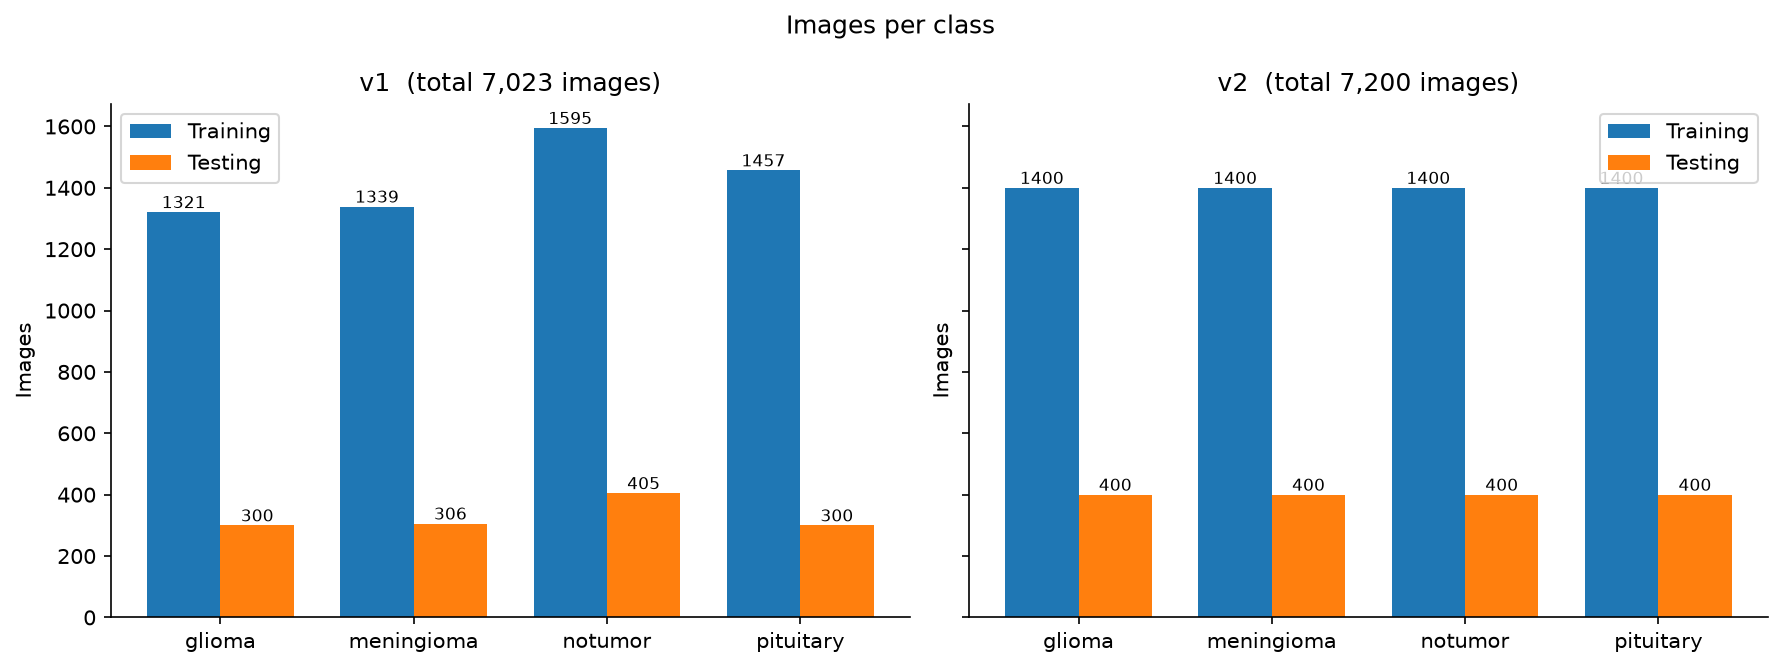

In [8]:
display(ShowImage(filename=str(d.plot_class_counts(files, PLOT_DIR))))

## 5. Sample images (4 per class, seed 42)

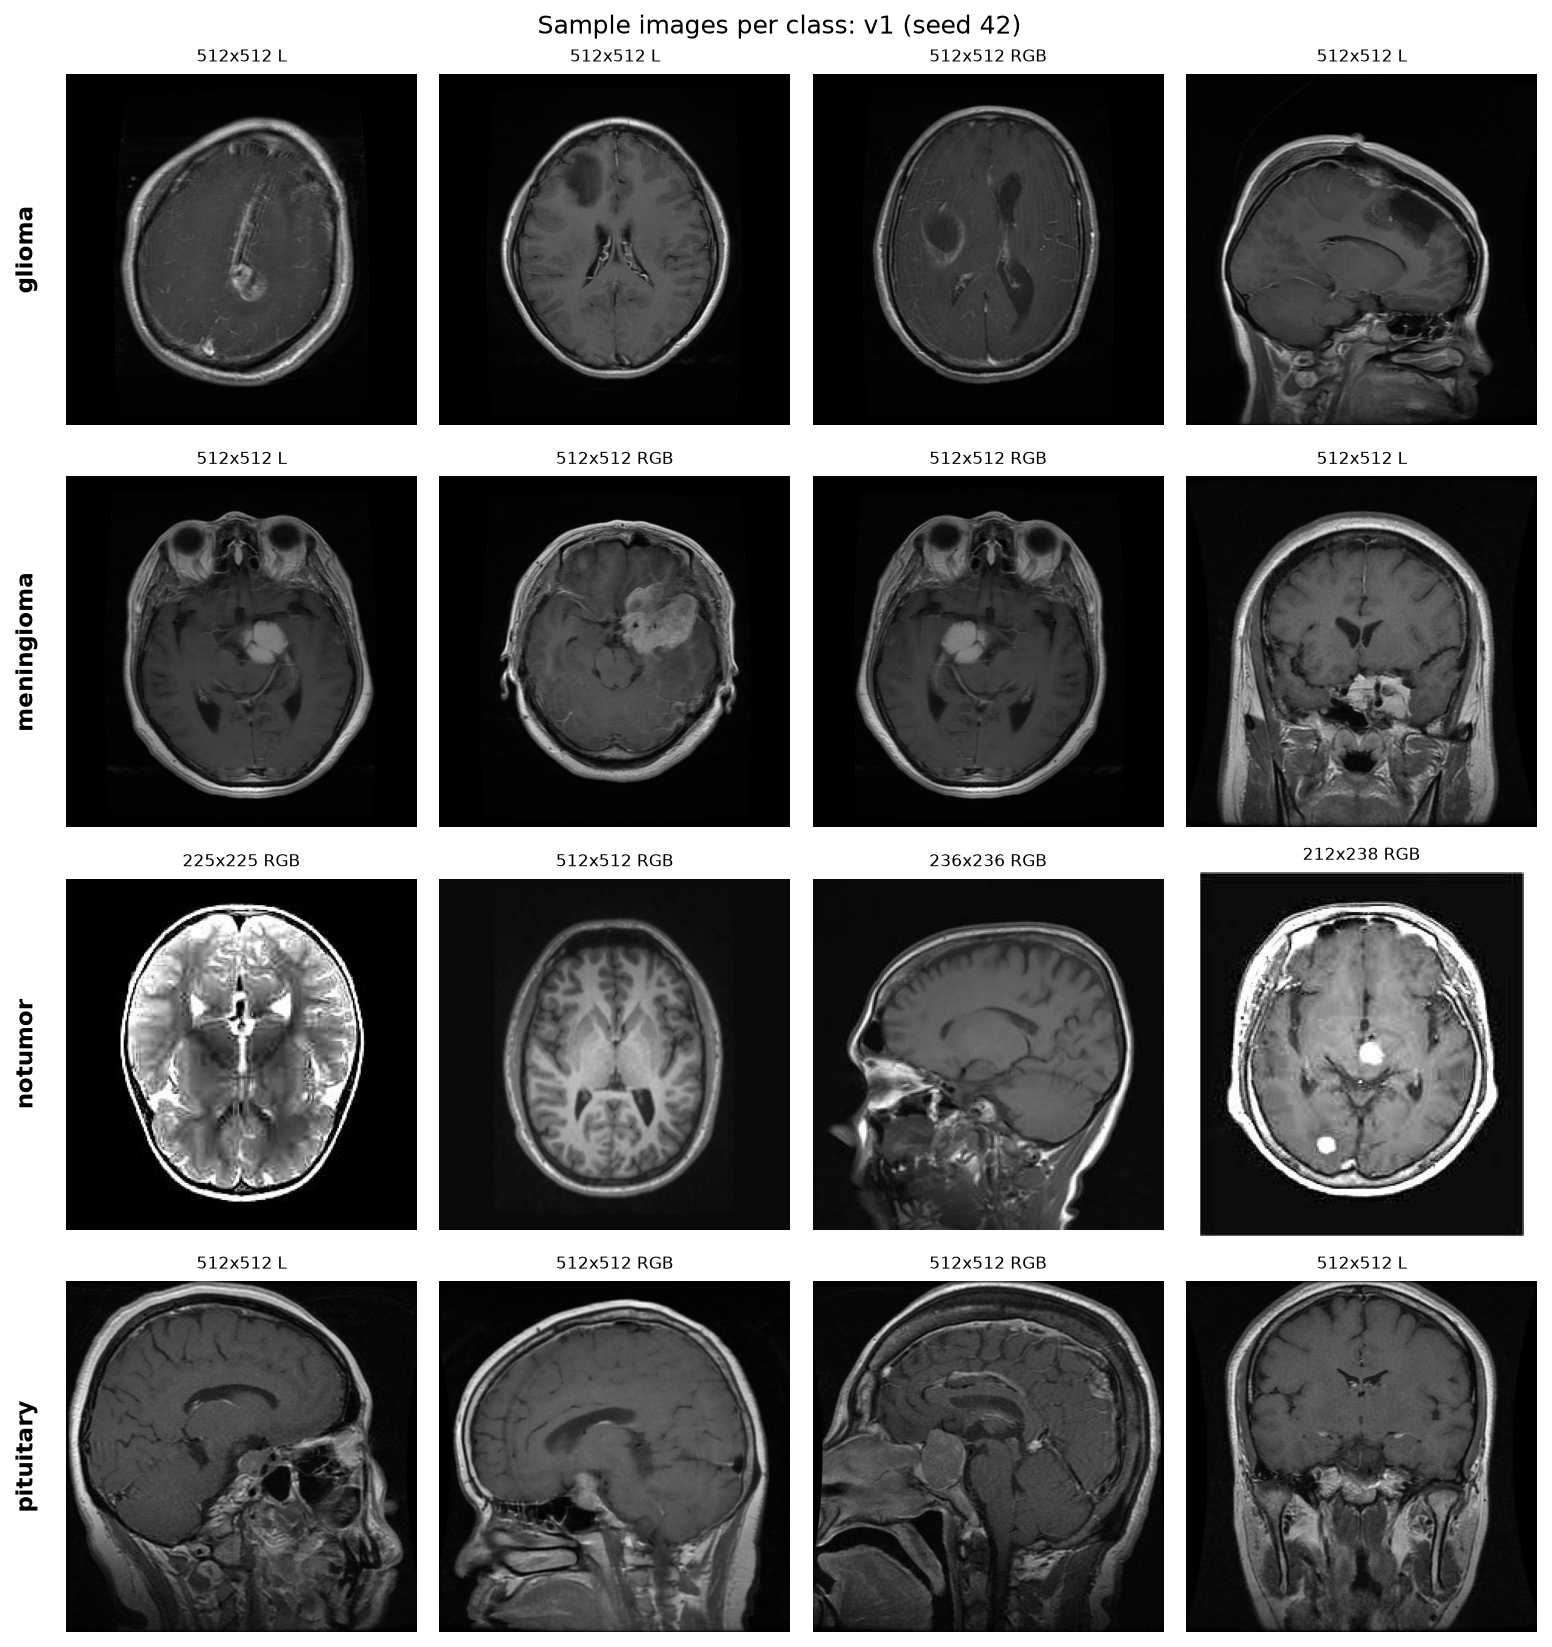

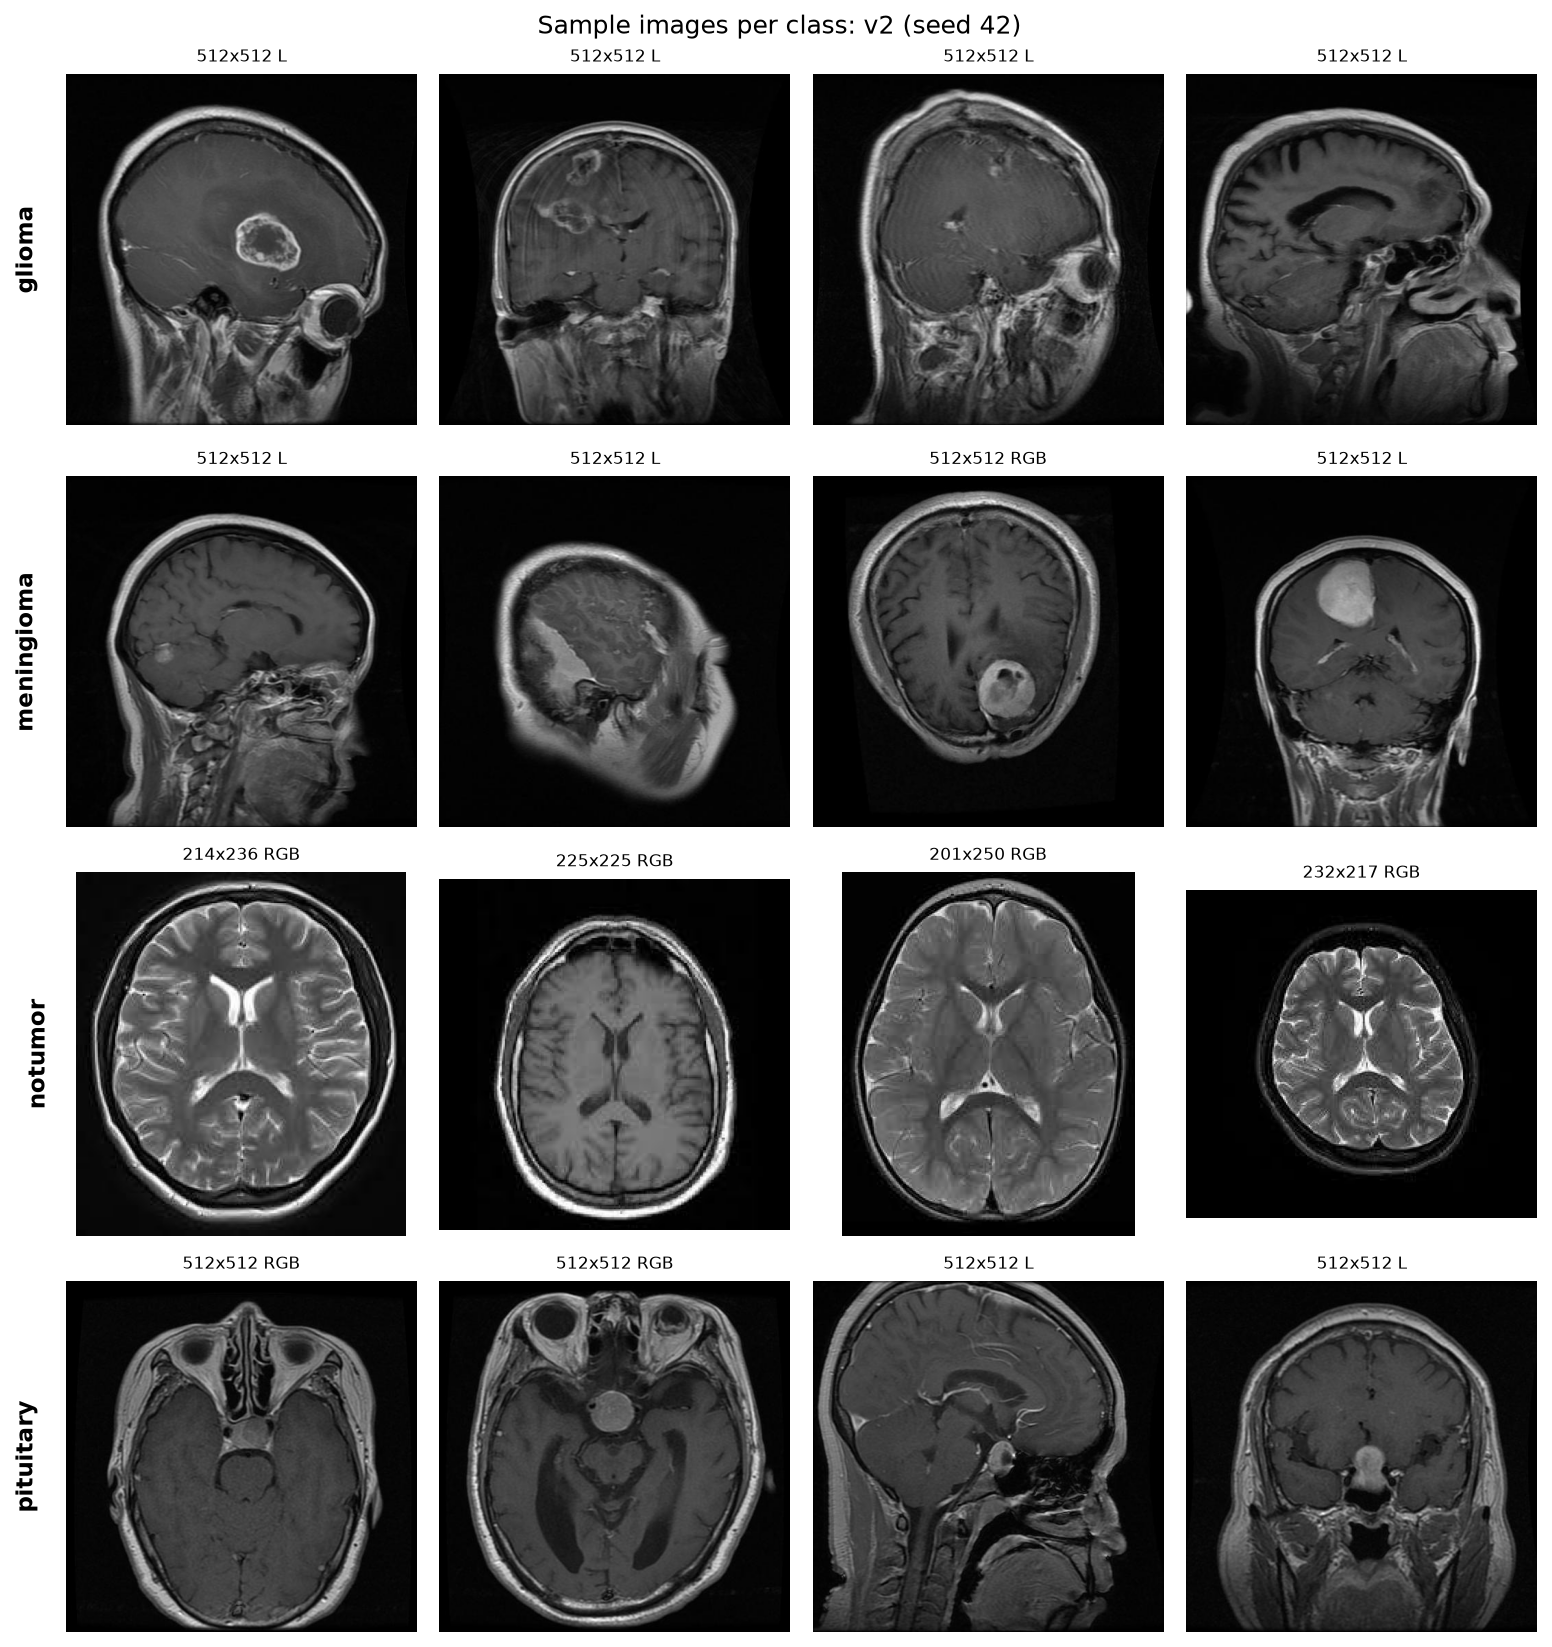

In [9]:
for v in versions:
    display(ShowImage(filename=str(d.plot_sample_grid(files, v, PLOT_DIR))))

## 6. Image size distribution

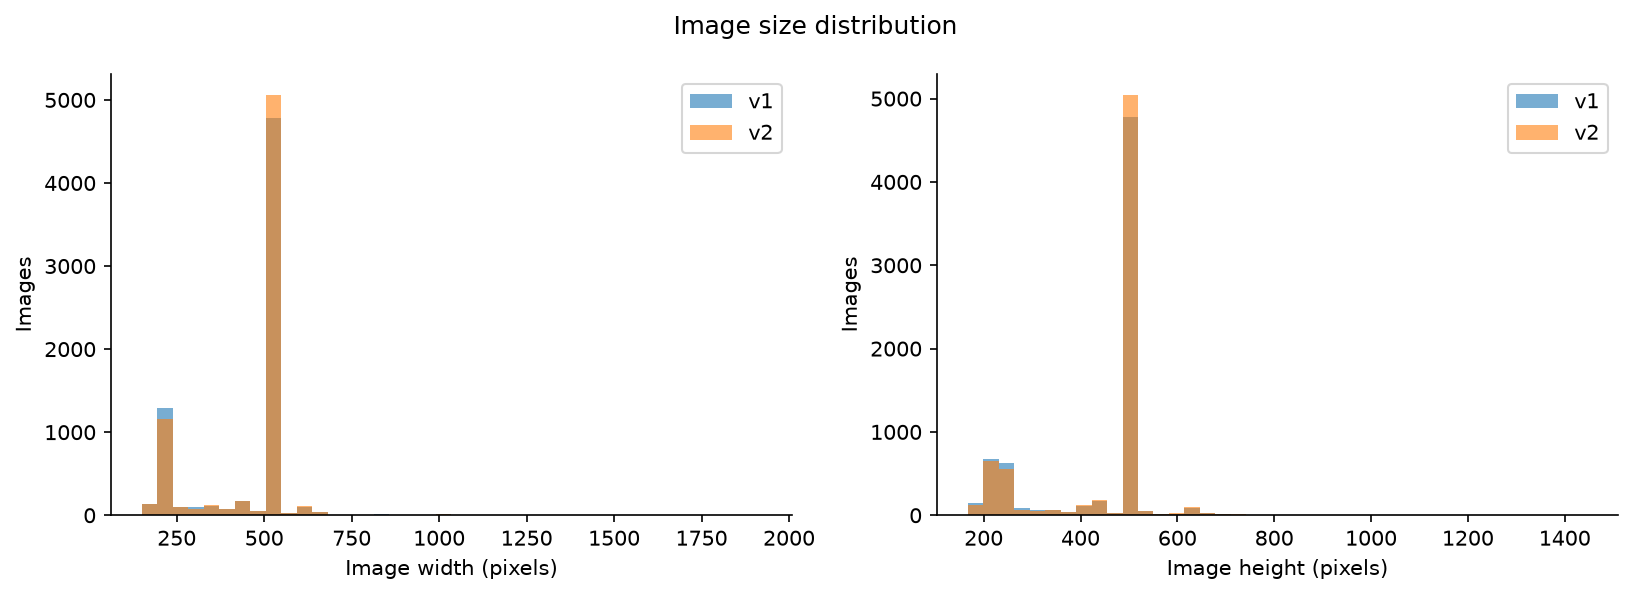

Saved plots: ['class_counts.png', 'image_sizes.png', 'samples_v1.png', 'samples_v2.png']


In [10]:
display(ShowImage(filename=str(d.plot_size_hist(info, PLOT_DIR))))
print('Saved plots:', sorted(p.name for p in PLOT_DIR.glob('*.png')))

## What we found (Week 1 summary)
| Check | v1 | v2 |
|---|---|---|
| Total images | 7,023 (matches the original release exactly) | 7,200 (matches the cleaned release exactly) |
| Training / Testing | 5,712 / 1,311 | 5,600 / 1,600 |
| Class balance | unbalanced (1,621-2,000 per class) | balanced (1,800 per class) |
| Corrupt / unreadable files | 0 | 0 |
| File extension | all `.jpg` | all `.jpg` |
| Real format | 7,018 JPEG + 5 PNG | 7,196 JPEG + 4 PNG |
| Colour modes | 3,093 L (grey), 3,926 RGB, 3 RGBA, 1 P | 3,067 L, 4,129 RGB, 3 RGBA, 1 P |
| Sizes | 387 different sizes, 512x512 = 67.5%, width 150-1,920 px | 447 different sizes, 512x512 = 69.6%, width 150-1,375 px |

**Key points**
1. **The data is usable:** every one of the 14,223 files opens and decodes fully.
2. **Some files are mislabelled by extension:** 9 files are named `.jpg` but are really PNG, and **all 9 are notumor**
   (as are all RGBA and P-mode images). Pillow opens them correctly, so nothing breaks, but our loader must open
   files by content (Pillow does), not by extension.
3. **Colour mode is linked to the class.** In v1, glioma is mostly greyscale (1,426 L vs 195 RGB) while notumor is almost
   all RGB (1,967 RGB vs 29 L). A model could learn "grey file -> glioma" instead of tumour features (a *shortcut*).
   We will convert **every** image to 3-channel RGB before training so the stored colour mode is not visible to the model.
4. **Image size is strongly linked to the class (source bias).** Only about 1% of notumor images are 512x512
   (v1 1.0%, v2 1.1%), against 84-100% for the three tumour classes. The notumor images clearly come from a
   different source (smaller, different contrast, some T2-weighted, as the sample grid shows). Resizing hides the
   size itself, but blur/compression and contrast differences remain, so a model may partly detect *the source*
   instead of *the tumour*. This is a key reason for our Grad-CAM "inside-brain ratio" check later.
5. **Sizes vary a lot** (150 px to 1,920 px wide, hundreds of different sizes). We will resize every image once to 224x224
   (299 for inception_v3) and cache the result in `outputs/`, so training does not decode large JPGs every epoch.
6. **Duplicates are visible already:** in the v1 sample grid, meningioma images 1 and 3 look identical by eye.
   Week 2's audit will measure duplicates properly.
7. **v1 vs v2:** v2 is balanced and slightly bigger; it is a re-curated release, not a simple subset of v1.

**Next (Week 2):** duplicate audit on v1: MD5 exact copies, pHash near-copies and deep-feature look-alikes, inside
and **across** Training/Testing. Then build the leakage-free split.